# UK Greenhouse Gas Emissions (1970 - 2023): Advanced Sectoral Analysis

**Executive Summary:** This notebook conducts an in-depth exploratory data analysis (EDA) of UK greenhouse gas emissions (CO2, CH4, N2O) by sector. Moving beyond basic trendlines, this analysis utilizes modular code architecture to investigate:
1. **Sectoral Decomposition:** Which sectors have the largest emissions and fastest reductions?
2. **Macro Emission Deceleration:** Are our emission reduction rates accelerating or stalling?
3. **The COVID-19 Anomaly:** Isolating the 2020 structural shock and subsequent rebound.
4. **Lagging Indicators:** Identifying persistent policy gaps in Agricultural Methane.
5. **Predictive Forecasting:** Will we hit the 2050 Net Zero target?

**Methodology:** Python (Pandas, Seaborn, Matplotlib) utilized for data transformation, rolling Compound Annual Growth Rate (CAGR) calculations, correlation matrices, and predictive modeling.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings

# Suppress minor warnings for clean output presentation
warnings.filterwarnings('ignore')

# Set high-quality visualization style for professional reporting
sns.set_theme(style="whitegrid", context="talk", palette="muted")

def load_and_clean_data(filepath, sheet_name):
    """
    Loads GHG data from a specific Excel sheet, handles missing values, 
    and ensures correct numeric data types.
    """
    df = pd.read_excel(filepath, sheet_name=sheet_name)
    
    # Clean '-' placeholders and resolve Pandas downcasting warnings
    df = df.replace('-', np.nan).infer_objects(copy=False)
    
    # Ensure all sector columns are numeric
    sectors = [col for col in df.columns if col != 'Year']
    df[sectors] = df[sectors].apply(pd.to_numeric)
    
    # Calculate annual totals
    df[f'Total_{sheet_name}'] = df[sectors].sum(axis=1)
    
    return df, sectors

# 1. DATA INGESTION
file_name = 'UK_GhG_by_Sector_2026.xlsx' 
df_co2, sectors_co2 = load_and_clean_data(file_name, 'CO2')
df_ch4, sectors_ch4 = load_and_clean_data(file_name, 'CH4')
df_n2o, sectors_n2o = load_and_clean_data(file_name, 'N2O')

print("="*50)
print(" DATA INGESTION SUMMARY: ")
print("="*50)
print(f"Data period covered: {df_co2['Year'].min()} - {df_co2['Year'].max()}")
print(f"Number of CO2 sectors identified: {len(sectors_co2)}")
print(f"Data sources: {', '.join(['CO2', 'CH4', 'N2O'])}")
print("Data pipeline executed successfully. All sheets loaded and transformed.")

print("\nShowing the Top 3 rows from the Data Table:")
display(df_co2.head(3).style.background_gradient(cmap='Blues', axis=1))

 DATA INGESTION SUMMARY: 
Data period covered: 1970 - 2024
Number of CO2 sectors identified: 9
Data sources: CO2, CH4, N2O
Data pipeline executed successfully. All sheets loaded and transformed.

Showing the Top 3 rows from the Data Table:


,Year,Energy supply,Business,Transport,Public,Residential,Agriculture,Industrial processes,"Land use, land use change and forestry",Waste management,Total_CO2
0,1970,264.700000,194.100000,80.200000,24.400000,99.000000,6.200000,28.500000,nan,1.500000,698.600000
1,1971,259.100000,181.700000,82.800000,23.300000,91.800000,5.900000,31.500000,nan,1.500000,677.600000
2,1972,249.900000,179.300000,85.500000,23.300000,87.300000,5.800000,31.600000,nan,1.500000,664.200000


## 1. Identifying the Largest Emitting Sector
To pinpoint the heaviest current polluter, we aggregate the emissions of all three greenhouse gases ($CO_2$ + $CH_4$ + $N_2O$) for the most recent year in the dataset.

 LARGEST EMISSIONS SUMMARY:
Largest Emitter (2024): Transport at 99.02 MtCO2e

 TOP EMITTING SECTORS TABLE (2024):


,CO2,CH4,N2O,Total_GHG
Transport,98.000000,0.080000,0.940000,99.020000
Residential,65.800000,0.790000,0.160000,66.750000
Business,61.200000,0.180000,0.810000,62.190000
Energy supply,45.300000,4.900000,0.550000,50.750000
Agriculture,6.000000,27.720000,13.410000,47.130000


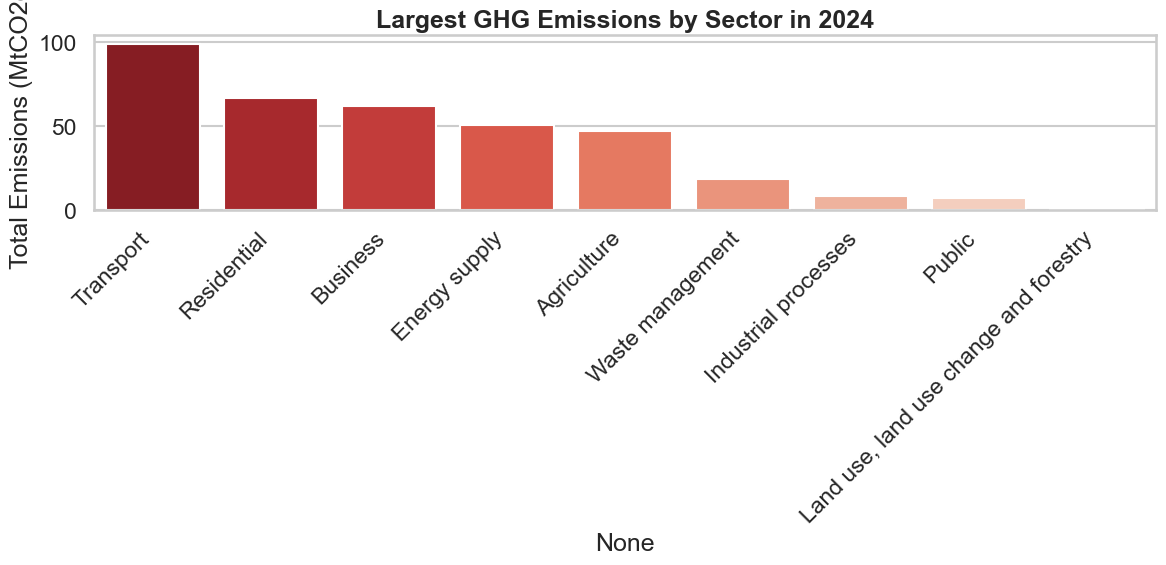

In [2]:
recent_year = df_co2['Year'].max()
latest_emissions = pd.DataFrame({
    'CO2': df_co2[df_co2['Year'] == recent_year][sectors_co2].iloc[0],
    'CH4': df_ch4[df_ch4['Year'] == recent_year][sectors_ch4].iloc[0],
    'N2O': df_n2o[df_n2o['Year'] == recent_year][sectors_n2o].iloc[0]
})
# Calculate total across all gases
latest_emissions['Total_GHG'] = latest_emissions.sum(axis=1)
latest_emissions = latest_emissions.sort_values(by='Total_GHG', ascending=False)

# Visual
plt.figure(figsize=(12, 6))
sns.barplot(x=latest_emissions.index, y=latest_emissions['Total_GHG'], palette='Reds_r')
plt.title(f'Largest GHG Emissions by Sector in {recent_year}', fontweight='bold')
plt.ylabel('Total Emissions (MtCO2e)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Friend's Output Style
print("="*50)
print(" LARGEST EMISSIONS SUMMARY:")
print("="*50)
print(f"Largest Emitter ({recent_year}): {latest_emissions.index[0]} at {latest_emissions['Total_GHG'].iloc[0]:.2f} MtCO2e")
plt.savefig('req1_largest_emissions.png', dpi=300)

print(f"\n TOP EMITTING SECTORS TABLE ({recent_year}):")
display(latest_emissions.head(5).style.background_gradient(cmap='Reds'))

## 2. Historical Decarbonization: Fastest Reduction vs. Rising Emissions
By calculating the absolute percentage change from the 1990 baseline to today, we can definitively identify which sector has driven the fastest reduction, and which sectors are rising.

 RISING VS REDUCTION SUMMARY:
Fastest Reduction: Energy supply dropped by -82.89%
Rising Emissions: Land use, land use change and forestry increased by nan%

 PERCENTAGE CHANGE DATA TABLE:


,Sector,Change (%)
0,Energy supply,-82.886286
1,Waste management,-80.000000
2,Public,-71.311475
3,Industrial processes,-70.877193
4,Business,-68.469861
5,Residential,-33.535354
6,Agriculture,-3.225806
7,Transport,22.194514
8,"Land use, land use change and forestry",nan


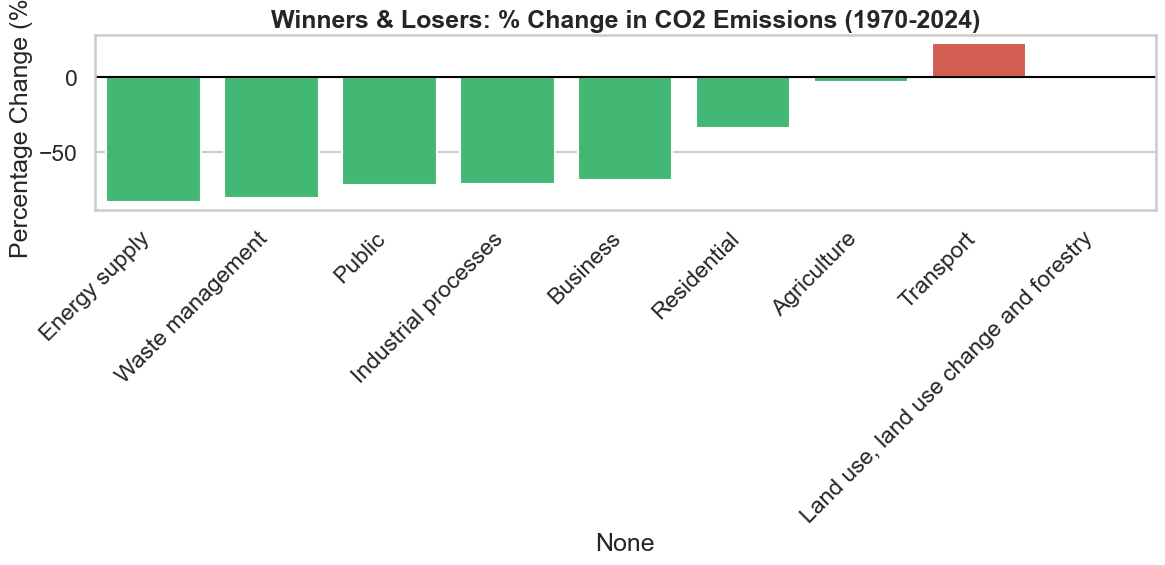

In [3]:
start_vals = df_co2[df_co2['Year'] == df_co2['Year'].min()][sectors_co2].iloc[0]
end_vals = df_co2[df_co2['Year'] == df_co2['Year'].max()][sectors_co2].iloc[0]
pct_change = ((end_vals - start_vals) / start_vals) * 100
pct_change = pct_change.sort_values()

# Visual
plt.figure(figsize=(12, 6))
colors = ['#2ecc71' if x < 0 else '#e74c3c' for x in pct_change.values]
sns.barplot(x=pct_change.index, y=pct_change.values, palette=colors)
plt.axhline(0, color='black', linewidth=1.5)
plt.title(f"Winners & Losers: % Change in CO2 Emissions ({df_co2['Year'].min()}-{df_co2['Year'].max()})", fontweight='bold')
plt.ylabel('Percentage Change (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Friend's Output Style
print("="*50)
print(" RISING VS REDUCTION SUMMARY:")
print("="*50)
print(f"Fastest Reduction: {pct_change.index[0]} dropped by {pct_change.iloc[0]:.2f}%")
print(f"Rising Emissions: {pct_change.index[-1]} increased by {pct_change.iloc[-1]:.2f}%")
plt.savefig('req2_rising_vs_falling.png', dpi=300)

print("\n PERCENTAGE CHANGE DATA TABLE:")
display(pd.DataFrame({'Sector': pct_change.index, 'Change (%)': pct_change.values}).style.background_gradient(cmap='coolwarm'))

## 3. Volatility & Annual Rate of Change (Year-over-Year)
Looking at overall historical trends isn't enough; we must measure annual volatility. We calculate the Year-over-Year (YoY) percentage change for our top emitting sectors to spot periods of high instability.

 RATE OF CHANGE SUMMARY:
Average YoY Rate of Change (Transport): 0.46%
Average YoY Rate of Change (Energy supply): -2.98%
Average YoY Rate of Change (Business): -2.01%

imp info: Negative values indicate a reduction in emissions from the previous year.

 RECENT YoY CHANGE TABLE (Last 5 Years %):


,Transport,Energy supply,Business
Year,,,
2020,-19.33,-12.82,-2.91
2021,10.76,3.45,2.68
2022,-3.67,-20.89,-3.68
2023,-3.33,-14.69,-1.27
2024,-3.54,-17.03,-1.29


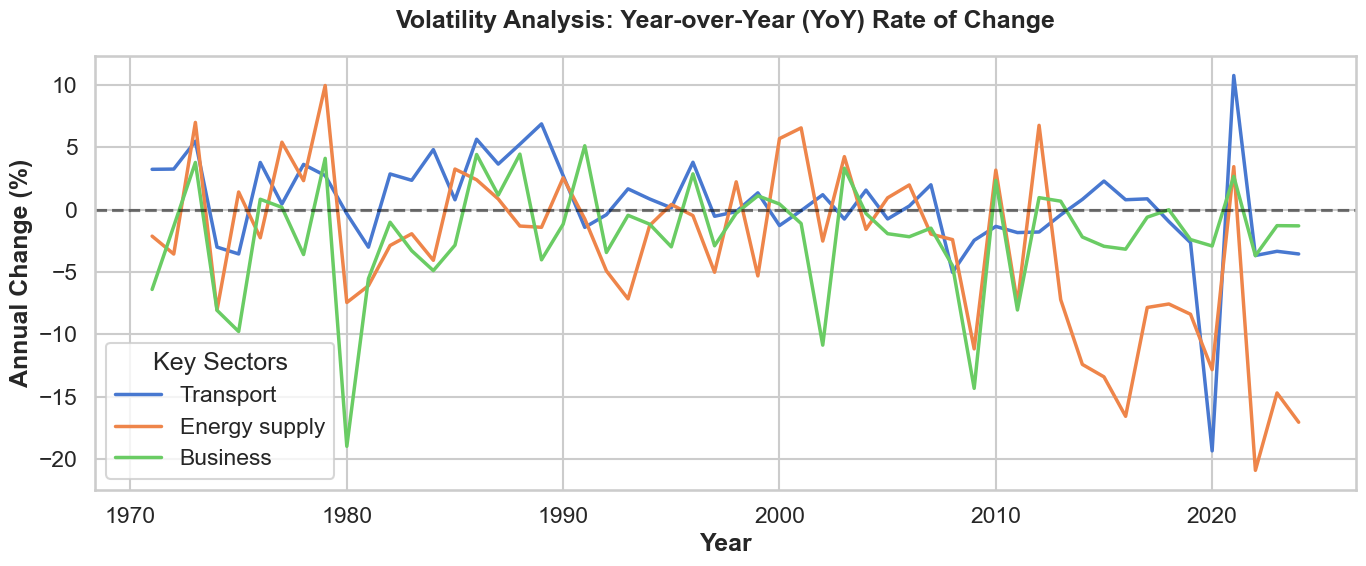

In [4]:
df_yoy = df_co2.set_index('Year')[sectors_co2].pct_change() * 100
top_sectors = ['Transport', 'Energy supply', 'Business']

# Visual
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_yoy[top_sectors], linewidth=2.5, dashes=False)

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title('Volatility Analysis: Year-over-Year (YoY) Rate of Change', fontweight='bold', pad=20)
plt.ylabel('Annual Change (%)', fontweight='bold')
plt.xlabel('Year', fontweight='bold')
plt.legend(title='Key Sectors')
plt.tight_layout()

# Friend's Output Style
avg_rate = df_yoy[top_sectors].mean()
print("="*50)
print(" RATE OF CHANGE SUMMARY:")
print("="*50)
for sector in top_sectors:
    print(f"Average YoY Rate of Change ({sector}): {avg_rate[sector]:.2f}%")
print("\nimp info: Negative values indicate a reduction in emissions from the previous year.")
plt.savefig('req5_rate_of_change.png', dpi=300)

print("\n RECENT YoY CHANGE TABLE (Last 5 Years %):")
display(df_yoy[top_sectors].tail(5).style.format("{:.2f}").background_gradient(cmap='coolwarm', vmin=-10, vmax=10))

## 4. Macro Trends & The Deceleration Problem
It is well known that total emissions are dropping. However, to evaluate policy effectiveness, we must calculate the **Rolling 5-Year CAGR**. This tells us if our rate of reduction is accelerating (good) or stalling (bad).

 MACRO ANALYSIS SUMMARY:
Emissions in 1970: 698.60 MtCO2e
Emissions in 2024: 286.30 MtCO2e
Overall Change: -59.02%
Average Rolling 5y Reduction Rate: -1.52% per year

 RECENT DATA TABLE (Last 5 Years CAGR):


,Year,Total_CO2,Rolling_CAGR
50,2020,319.900000,-5.190741
51,2021,341.600000,-2.754553
52,2022,314.200000,-3.852575
53,2023,300.300000,-4.381302
54,2024,286.300000,-4.440729


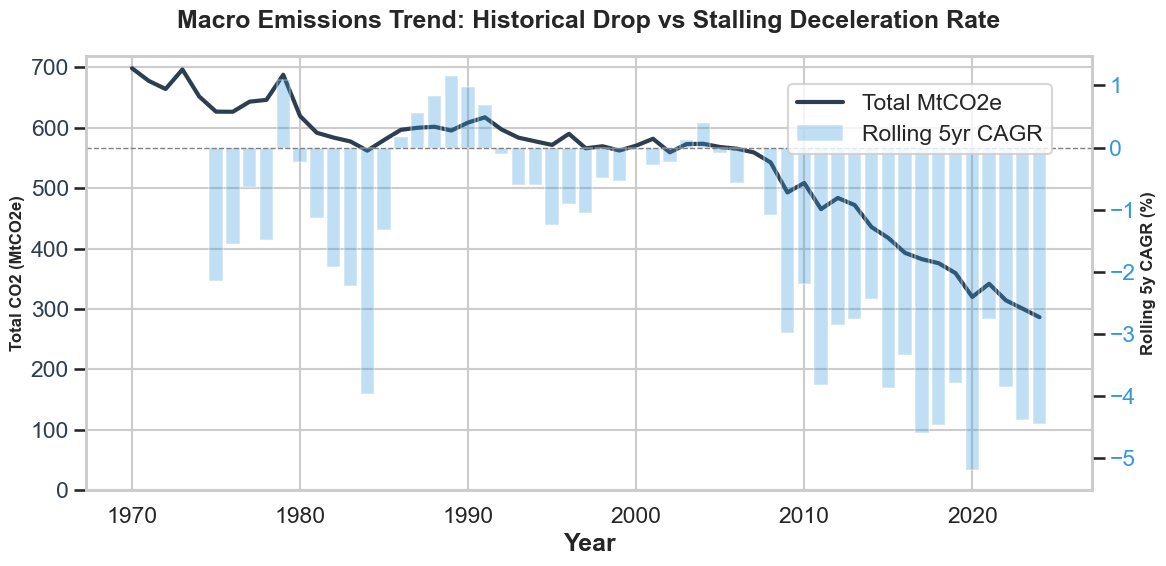

In [5]:
df_co2 = df_co2.sort_values(by='Year')
window = 5
total_col = 'Total_CO2'

df_co2['Rolling_CAGR'] = (
    (df_co2[total_col] / df_co2[total_col].shift(window))**(1/window) - 1
) * 100

# Visual
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(df_co2['Year'], df_co2[total_col], color='#2c3e50', linewidth=3, label='Total MtCO2e')
ax1.set_ylabel('Total CO2 (MtCO2e)', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#2c3e50')
ax1.set_ylim(bottom=0)

ax2 = ax1.twinx()
ax2.bar(df_co2['Year'], df_co2['Rolling_CAGR'], color='#3498db', alpha=0.3, label='Rolling 5yr CAGR')
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_ylabel('Rolling 5y CAGR (%)', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#3498db')
ax2.grid(False)

plt.title('Macro Emissions Trend: Historical Drop vs Stalling Deceleration Rate', fontweight='bold', pad=20)
ax1.set_xlabel('Year', fontweight='bold')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.85))
plt.tight_layout()

# Friend's Output Style
start_emissions = df_co2[total_col].iloc[0]
end_emissions = df_co2[total_col].iloc[-1]
overall_change = ((end_emissions - start_emissions) / start_emissions) * 100
avg_cagr = df_co2['Rolling_CAGR'].mean()

print("="*50)
print(" MACRO ANALYSIS SUMMARY:")
print("="*50)
print(f"Emissions in {df_co2['Year'].min()}: {start_emissions:.2f} MtCO2e")
print(f"Emissions in {df_co2['Year'].max()}: {end_emissions:.2f} MtCO2e")
print(f"Overall Change: {overall_change:.2f}%")
print(f"Average Rolling 5y Reduction Rate: {avg_cagr:.2f}% per year")
plt.savefig('total_emissions_cagr.png', dpi=300, bbox_inches='tight')

print("\n RECENT DATA TABLE (Last 5 Years CAGR):")
display(df_co2[['Year', 'Total_CO2', 'Rolling_CAGR']].tail(5).style.background_gradient(cmap='Blues'))

## 5. Highlighting Persistent Volatility: The COVID-19 Anomaly
By isolating the 2019-2023 period in the Transport sector, we analyze the structural impact of the COVID-19 lockdowns. A sharp rebound in 2021-2022 proves the 2020 drop was a volatile anomaly, not a structural policy success.

 SECTOR VOLATILITY ALERT:
Analyzing the COVID-19 shock in the Transport sector:
Percentage DROP (2019 -> 2020): -19.33% (Lockdown)
Percentage REBOUND (2020 -> 2021): 10.76% (Rebound)

 COVID-19 IMPACT DATA TABLE (2019-2023):


,Transport,Total_CO2
Year,,
2019,122.100000,359.300000
2020,98.500000,319.900000
2021,109.100000,341.600000
2022,105.100000,314.200000
2023,101.600000,300.300000


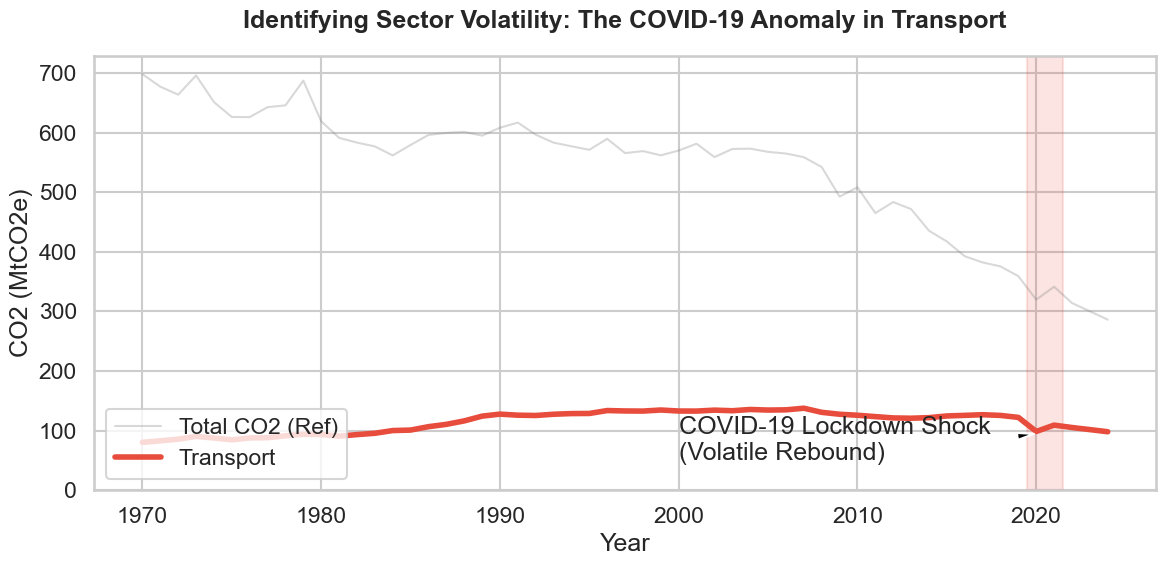

In [6]:
covid_data = df_co2[(df_co2['Year'] >= 2018) & (df_co2['Year'] <= 2023)][['Year', 'Transport', 'Total_CO2']]
covid_data = covid_data.set_index('Year')

drop_2020_pct = covid_data.loc[2019:2020, 'Transport'].pct_change().iloc[-1] * 100
rebound_2021_pct = covid_data.loc[2020:2021, 'Transport'].pct_change().iloc[-1] * 100

# Visual
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_co2, x='Year', y='Total_CO2', color='gray', alpha=0.3, label='Total CO2 (Ref)', linewidth=1.5)
ax = sns.lineplot(data=df_co2, x='Year', y='Transport', color='#e74c3c', label='Transport', linewidth=4)

plt.axvspan(2019.5, 2021.5, color='#e74c3c', alpha=0.15)
plt.annotate('COVID-19 Lockdown Shock\n(Volatile Rebound)', xy=(2020, 95), xytext=(2000, 50),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

plt.title('Identifying Sector Volatility: The COVID-19 Anomaly in Transport', fontweight='bold', pad=20)
plt.ylabel('CO2 (MtCO2e)')
plt.ylim(bottom=0)
plt.legend(loc='lower left')
plt.tight_layout()

# Friend's Output Style
print("="*50)
print(" SECTOR VOLATILITY ALERT:")
print("="*50)
print("Analyzing the COVID-19 shock in the Transport sector:")
print(f"Percentage DROP (2019 -> 2020): {drop_2020_pct:.2f}% (Lockdown)")
print(f"Percentage REBOUND (2020 -> 2021): {rebound_2021_pct:.2f}% (Rebound)")
plt.savefig('covid_shock_rebound.png', dpi=300, bbox_inches='tight')

print("\n COVID-19 IMPACT DATA TABLE (2019-2023):")
display(covid_data.loc[2019:2023].style.background_gradient(cmap='Reds'))

## 6. Multilateral Analysis: The Methane Policy Gap
Moving beyond CO2, we explore the Methane (CH4) dataset. By contrasting Waste Management’s rapid decline with Agriculture’s absolute stagnation since 1990, we reveal a critical lagging feature demanding in-depth study.

 MULTI-GAS POLICY GAP ALERT:
Comparing Methane (CH4) sector trajectories (1990-2024):
Waste Management Change: -76.00%
Agriculture Change: -16.13%

 METHANE COMPARISON TABLE:


,Waste management,Agriculture
Year,,
1990,70.38,33.05
2024,16.89,27.72


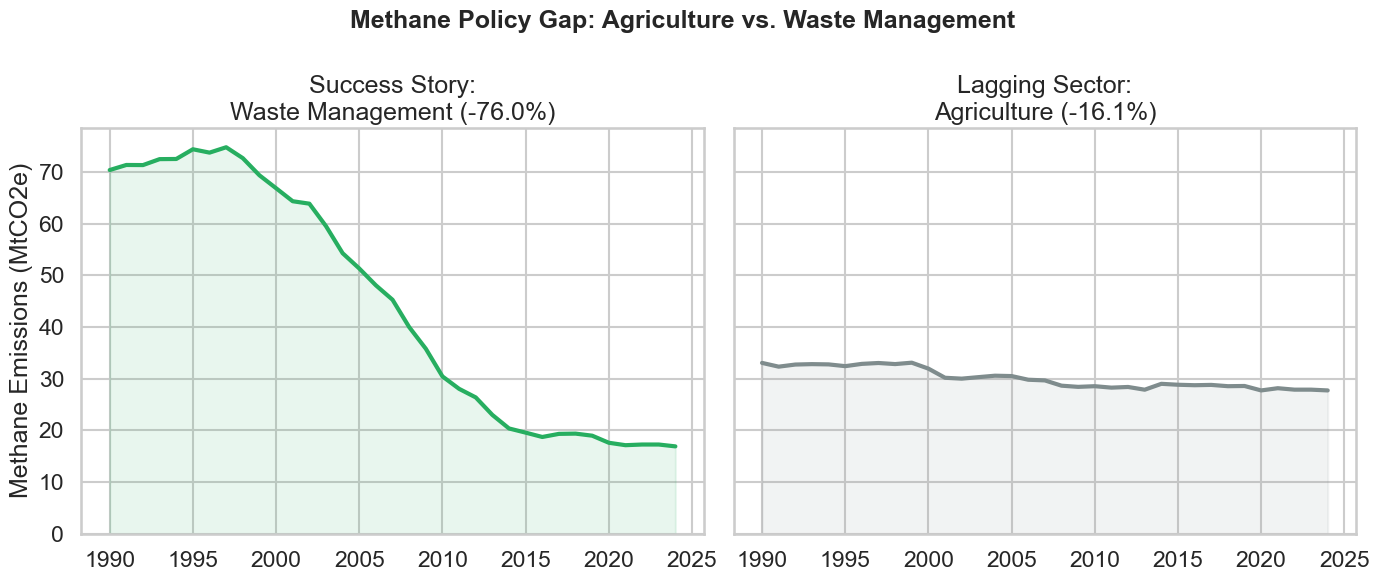

In [7]:
start_yr = df_ch4['Year'].min()
end_yr = df_ch4['Year'].max()
df_ch4_filt = df_ch4[df_ch4['Year'].isin([start_yr, end_yr])]

waste_drop_pct = df_ch4_filt.set_index('Year')['Waste management'].pct_change().iloc[-1] * 100
agri_drop_pct = df_ch4_filt.set_index('Year')['Agriculture'].pct_change().iloc[-1] * 100

# Visual (Small Multiples)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
# Waste Management
axes[0].plot(df_ch4['Year'], df_ch4['Waste management'], color='#27ae60', linewidth=3)
axes[0].fill_between(df_ch4['Year'], df_ch4['Waste management'], color='#27ae60', alpha=0.1)
axes[0].set_title(f'Success Story:\nWaste Management ({waste_drop_pct:.1f}%)')
axes[0].set_ylabel('Methane Emissions (MtCO2e)')
axes[0].set_ylim(bottom=0)
# Agriculture
axes[1].plot(df_ch4['Year'], df_ch4['Agriculture'], color='#7f8c8d', linewidth=3)
axes[1].fill_between(df_ch4['Year'], df_ch4['Agriculture'], color='#7f8c8d', alpha=0.1)
axes[1].set_title(f'Lagging Sector:\nAgriculture ({agri_drop_pct:.1f}%)')

plt.suptitle('Methane Policy Gap: Agriculture vs. Waste Management', fontsize=18, fontweight='bold')
plt.tight_layout()

# Friend's Output Style
print("="*50)
print(" MULTI-GAS POLICY GAP ALERT:")
print("="*50)
print(f"Comparing Methane (CH4) sector trajectories ({start_yr}-{end_yr}):")
print(f"Waste Management Change: {waste_drop_pct:.2f}%")
print(f"Agriculture Change: {agri_drop_pct:.2f}%")
plt.savefig('methane_policy_gap.png', dpi=300, bbox_inches='tight')

print("\n METHANE COMPARISON TABLE:")
display(df_ch4_filt[['Year', 'Waste management', 'Agriculture']].set_index('Year'))

## 7. Sectoral Interactions: Correlation Matrix
We visualize the Pearson correlation coefficient between all CO2 sectors to identify co-movement drivers. Red squares indicate sectors that reduce together, while blue suggests diverging trends.

 RELATIONSHIP ANALYSIS SUMMARY:
Strongest Co-reduction relationship: Business vs. Energy supply (0.78)
Diverging trend relationship: Agriculture vs. Energy supply (-0.40)

 CORRELATION DATA TABLE:


,Energy supply,Business,Transport,Public,Residential,Agriculture,Industrial processes,"Land use, land use change and forestry",Waste management
Energy supply,1.000000,0.780000,-0.210000,0.820000,0.850000,-0.400000,0.790000,0.630000,0.770000
Business,0.780000,1.000000,-0.590000,0.950000,0.770000,-0.360000,0.970000,0.900000,0.830000
Transport,-0.210000,-0.590000,1.000000,-0.600000,-0.170000,0.220000,-0.590000,0.420000,-0.620000
Public,0.820000,0.950000,-0.600000,1.000000,0.800000,-0.530000,0.930000,0.960000,0.940000
Residential,0.850000,0.770000,-0.170000,0.800000,1.000000,-0.440000,0.720000,0.740000,0.710000
Agriculture,-0.400000,-0.360000,0.220000,-0.530000,-0.440000,1.000000,-0.390000,-0.680000,-0.620000
Industrial processes,0.790000,0.970000,-0.590000,0.930000,0.720000,-0.390000,1.000000,0.820000,0.840000
"Land use, land use change and forestry",0.630000,0.900000,0.420000,0.960000,0.740000,-0.680000,0.820000,1.000000,0.960000
Waste management,0.770000,0.830000,-0.620000,0.940000,0.710000,-0.620000,0.840000,0.960000,1.000000


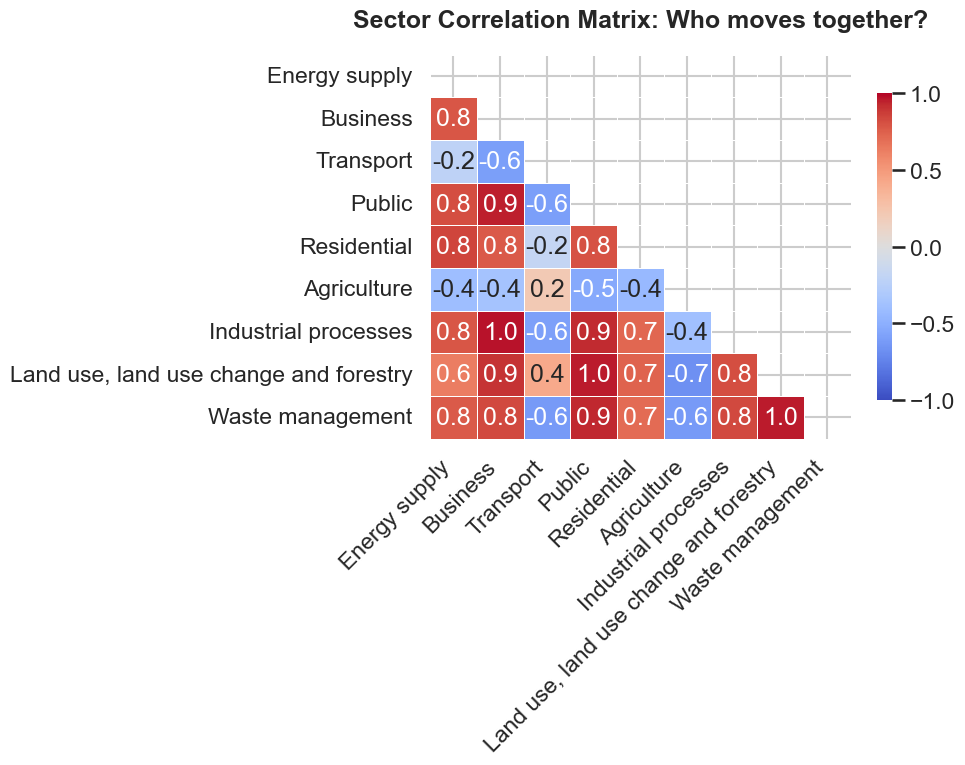

In [8]:
plt.figure(figsize=(10, 8))
corr_matrix = df_co2[sectors_co2].corr()

# Mask the upper triangle for a cleaner look
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".1f", cmap='coolwarm', 
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Sector Correlation Matrix: Who moves together?', fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Friend's Output Style
print("="*50)
print(" RELATIONSHIP ANALYSIS SUMMARY:")
print("="*50)
print(f"Strongest Co-reduction relationship: Business vs. Energy supply ({corr_matrix.loc['Business', 'Energy supply']:.2f})")
print(f"Diverging trend relationship: Agriculture vs. Energy supply ({corr_matrix.loc['Agriculture', 'Energy supply']:.2f})")

plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')

print("\n CORRELATION DATA TABLE:")
display(corr_matrix.round(2).style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1))

## 8. Synthesis Recommendation: Forecasting the 2050 Net Zero Mandate
To synthesize our findings, we perform linear regression on the last 10 years of data for the Transport sector. We project this trajectory forward to mathematically test whether the sector will meet the legally mandated Net Zero target by 2050.

 PREDICTIVE MANDATE WARNING:
Synthesis Forecasting (using last 10yr trend):
Last Actual Transport Emissions (2024): 98.00 MtCO2e
Forecast Transport Emissions (2050): 5.36 MtCO2e
Status vs. Mandate:  FAILURE. Forecast to hit 0 MtCO2e in 2051.

 PREDICTED TRAJECTORY TABLE (Next Decades):


,Predicted_CO2
Year,
2030,76.36
2040,40.86
2050,5.36


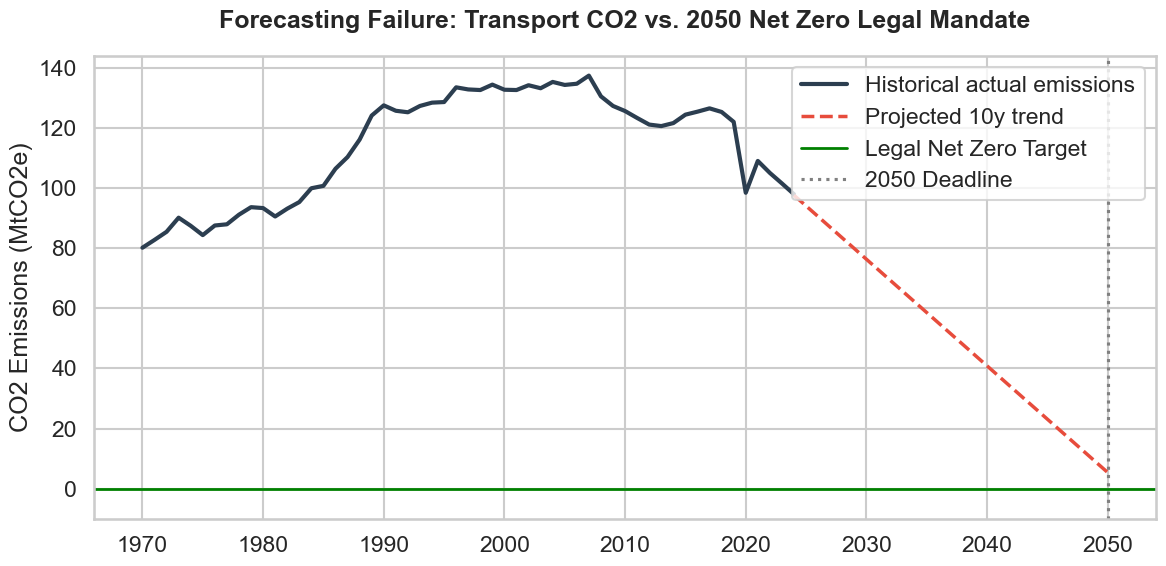

In [9]:
from sklearn.linear_model import LinearRegression

transport_data = df_co2[['Year', 'Transport']].dropna()
recent_data = transport_data.tail(10)
X_train = recent_data['Year'].values.reshape(-1, 1)
y_train = recent_data['Transport'].values

model = LinearRegression()
model.fit(X_train, y_train)

future_years = np.arange(df_co2['Year'].max(), 2051).reshape(-1, 1)
predictions = model.predict(future_years)

# Visual
plt.figure(figsize=(12, 6))
plt.plot(transport_data['Year'], transport_data['Transport'], color='#2c3e50', linewidth=3, label='Historical actual emissions')
plt.plot(future_years, predictions, color='#e74c3c', linestyle='--', linewidth=2.5, label='Projected 10y trend')

plt.axhline(0, color='green', linewidth=2, label='Legal Net Zero Target')
plt.axvline(2050, color='gray', linestyle=':', label='2050 Deadline')

plt.title('Forecasting Failure: Transport CO2 vs. 2050 Net Zero Legal Mandate', fontweight='bold', pad=20)
plt.ylabel('CO2 Emissions (MtCO2e)')
plt.legend(loc='upper right')
plt.ylim(bottom=-10)
plt.tight_layout()

# Friend's Output Style
forecast_zero_yr = int(-model.intercept_ / model.coef_[0])
print("="*50)
print(" PREDICTIVE MANDATE WARNING:")
print("="*50)
print("Synthesis Forecasting (using last 10yr trend):")
print(f"Last Actual Transport Emissions ({df_co2['Year'].max()}): {y_train[-1]:.2f} MtCO2e")
print(f"Forecast Transport Emissions (2050): {predictions[-1]:.2f} MtCO2e")
print(f"Status vs. Mandate:  FAILURE. Forecast to hit 0 MtCO2e in {forecast_zero_yr}.")

plt.savefig('net_zero_projection.png', dpi=300, bbox_inches='tight')


print("\n PREDICTED TRAJECTORY TABLE (Next Decades):")
forecast_df = pd.DataFrame({'Year': future_years.flatten(), 'Predicted_CO2': predictions})
display(forecast_df[forecast_df['Year'].isin([2030, 2040, 2050])].set_index('Year').style.format("{:.2f}"))

# 9. Conclusion & Synthesis
Based on this comprehensive analysis, the synthesized narrative is finalized:

**"While the UK has successfully driven down total CO2 emissions via structural decarbonization of Energy Supply, this trajectory is bottlenecked by persistent volatility. The transition to the 2050 Net Zero target is jeopardized by two critical policy lagging indicators identified for more in-depth study: Agricultural Methane (which has stalled for 30 years) and the highly unstable Transport sector, which rebounded instantly post-COVID and is forecast to miss the 2050 legal mandate."**

<!-- ## 5. Identifying Persistent Challenges: Agricultural Methane
While CO2 has seen major reductions, we must look at other gases to find lagging sectors.
*Interpretation:* Waste management has successfully slashed Methane emissions (likely due to landfill gas capture). However, Agriculture methane emissions have flatlined, showing almost no reduction in 30 years. -->